#Import Libraries

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt



#Load the dataset

In [2]:
#Load Dataset

import tensorflow as tf
import matplotlib.pyplot as plt

# Load CIFAR-100 dataset
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.cifar100.load_data()
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 2060s 12us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


#Normalize images

In [4]:

# Normalize training images by dividing pixel values by 255
x_train = x_train.astype('float32') / 255.0

# Normalize testing images by dividing pixel values by 255
x_test = x_test.astype('float32') / 255.0

# Display the shape of training images
print("Training data shape:", x_train.shape)

# Display the shape of testing images
print("Testing data shape:", x_test.shape)

# Display minimum and maximum pixel values after normalization
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training data shape: (50000, 32, 32, 3)
Testing data shape: (10000, 32, 32, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


#Build CNN Model

In [5]:
# Import TensorFlow and Keras layers
import tensorflow as tf
from tensorflow.keras import layers, models

# Create a Sequential CNN model
model = models.Sequential([

    # Define input image size: 32x32 RGB
    layers.Input(shape=(32, 32, 3)),

    # First convolutional layer
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),

    # Normalize layer outputs for stable training
    layers.BatchNormalization(),

    # Reduce image dimensions
    layers.MaxPooling2D((2, 2)),

    # Second convolutional layer
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),

    # Normalize layer outputs
    layers.BatchNormalization(),

    # Reduce image dimensions
    layers.MaxPooling2D((2, 2)),

    # Third convolutional layer
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),

    # Normalize layer outputs
    layers.BatchNormalization(),

    # Reduce image dimensions
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a one-dimensional vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(256, activation='relu'),

    # Dropout to reduce overfitting
    layers.Dropout(0.5),

    # Output layer for 100 CIFAR-100 classes
    layers.Dense(100, activation='softmax')
])

# Display the CNN architecture and parameter counts
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 644,388 (2.46 MB)

 Trainable params: 643,940 (2.46 MB)

 Non-trainable params: 448 (1.75 KB)

 #Compile the Model

In [6]:
# Compile the CNN model

model.compile(

    # Adam optimizer updates model weights during training
    optimizer='adam',

    # Loss function for 100-class classification
    loss='sparse_categorical_crossentropy',

    # Measure model accuracy during training
    metrics=['accuracy']
)

# Display confirmation message
print("CNN model compiled successfully!")

CNN model compiled successfully!


#Training the Model

In [7]:
# Train the CNN model using the training dataset

history = model.fit(x_train,y_train,epochs=10,batch_size=128,validation_split=0.2,verbose=1)

# Print a message after training finishes
print("CNN model training completed!")

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 50ms/step - accuracy: 0.0661 - loss: 4.2495 - val_accuracy: 0.0243 - val_loss: 6.4156
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - accuracy: 0.1343 - loss: 3.6954 - val_accuracy: 0.1942 - val_loss: 3.3753
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1831 - loss: 3.3737 - val_accuracy: 0.2322 - val_loss: 3.1514
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2202 - loss: 3.1461 - val_accuracy: 0.2831 - val_loss: 2.8748
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.2535 - loss: 2.9484 - val_accuracy: 0.2788 - val_loss: 2.9691
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.2905 - loss: 2.7782 - val_accuracy: 0.2929 - val_loss: 2.8401
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3163 - loss: 2.6409 - val_accuracy: 0.3348 - val_loss: 2.6118
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.3394 - loss: 2.5058 - val_accu

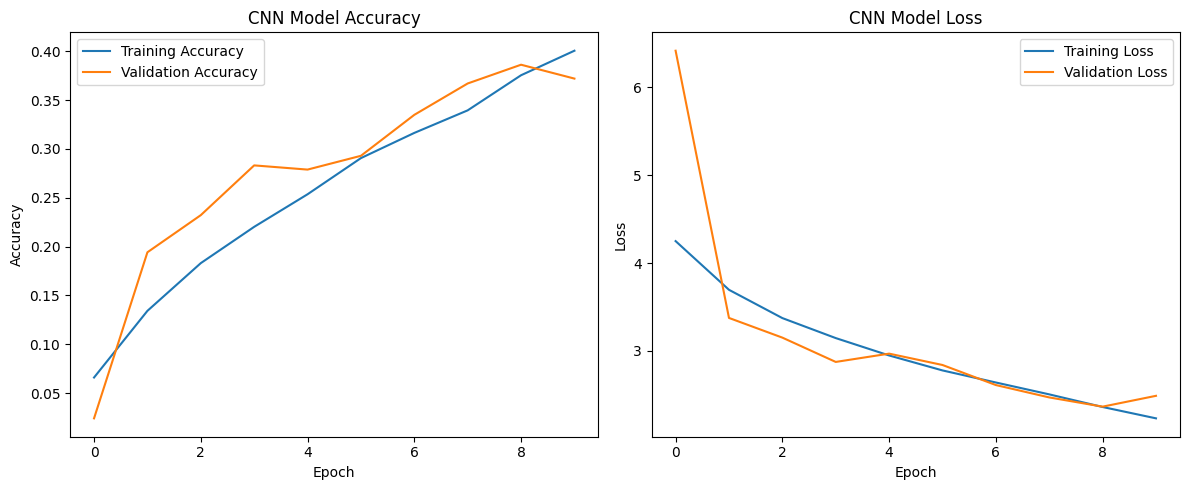

In [8]:
# Import matplotlib for plotting graphs
import matplotlib.pyplot as plt

# Create a figure with two graphs
plt.figure(figsize=(12, 5))

# Plot training and validation accuracy
plt.subplot(1, 2, 1)

# Training accuracy for each epoch
plt.plot(history.history['accuracy'], label='Training Accuracy')

# Validation accuracy for each epoch
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

# Add graph title and labels
plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

# Display legend
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)

# Training loss for each epoch
plt.plot(history.history['loss'], label='Training Loss')

# Validation loss for each epoch
plt.plot(history.history['val_loss'], label='Validation Loss')

# Add graph title and labels
plt.title('CNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

# Display legend
plt.legend()

# Adjust spacing between graphs
plt.tight_layout()

# Display both graphs
plt.show()

#Model Evaluation

In [9]:
# Evaluate the trained CNN model using test images

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

# Print the final test loss
print("Test Loss:", test_loss)

# Print the final test accuracy as a percentage
print("Test Accuracy: {:.2f}%".format(test_accuracy * 100))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3715 - loss: 2.4892
Test Loss: 2.4892325401306152
Test Accuracy: 37.15%


In [10]:
# Import required evaluation metrics
from sklearn.metrics import classification_report

# Predict the classes of test images
y_pred_prob = model.predict(x_test)

# Convert predicted probabilities into class labels
y_pred = y_pred_prob.argmax(axis=1)

# Convert actual labels into a one-dimensional array
y_true = y_test.flatten()

# Display precision, recall, and F1-score for all 100 classes
print(classification_report(
    y_true,
    y_pred,
    digits=4,
    zero_division=0
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
              precision    recall  f1-score   support

           0     0.7333    0.6600    0.6947       100
           1     0.5205    0.3800    0.4393       100
           2     0.2703    0.3000    0.2844       100
           3     0.2100    0.2100    0.2100       100
           4     0.1319    0.1200    0.1257       100
           5     0.4906    0.2600    0.3399       100
           6     0.3333    0.5100    0.4032       100
           7     0.2988    0.4900    0.3712       100
           8     0.6769    0.4400    0.5333       100
           9     0.7091    0.3900    0.5032       100
          10     0.3488    0.1500    0.2098       100
          11     0.3649    0.2700    0.3103       100
          12     0.6000    0.3300    0.4258       100
          13     0.4333    0.1300    0.2000       100
          14     0.2857    0.3200    0.3019       100
          15     0.2192    0.1600    0.1850       100
          16     0.5357    0.3000    0.3

#  Callbacks

In [11]:
# Import the required Keras callbacks
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Stop training if validation loss does not improve for 3 epochs
early_stop = EarlyStopping( monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Save the model whenever validation loss improves
checkpoint = ModelCheckpoint('best_cnn_model.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

# Train the CNN model using both callbacks
history_callback = model.fit(x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

# Display a confirmation message
print("Training with callbacks completed!")

Epoch 1/10
307/313 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4303 - loss: 2.0764
Epoch 1: val_loss improved from None to 2.42916, saving model to best_cnn_model.keras

Epoch 1: finished saving model to best_cnn_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.4238 - loss: 2.1107 - val_accuracy: 0.3845 - val_loss: 2.4292
Epoch 2/10
312/313 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4581 - loss: 1.9721
Epoch 2: val_loss improved from 2.42916 to 2.30457, saving model to best_cnn_model.keras

Epoch 2: finished saving model to best_cnn_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.4503 - loss: 2.0048 - val_accuracy: 0.4082 - val_loss: 2.3046
Epoch 3/10
311/313 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4830 - loss: 1.8477
Epoch 3: val_loss did not improve from 2.30457
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4760 - loss: 1.8821 - val_accuracy: 0.3680 - val_loss: 2.5822
Epoch 4/10
308/313 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - 

#CNN Architechture

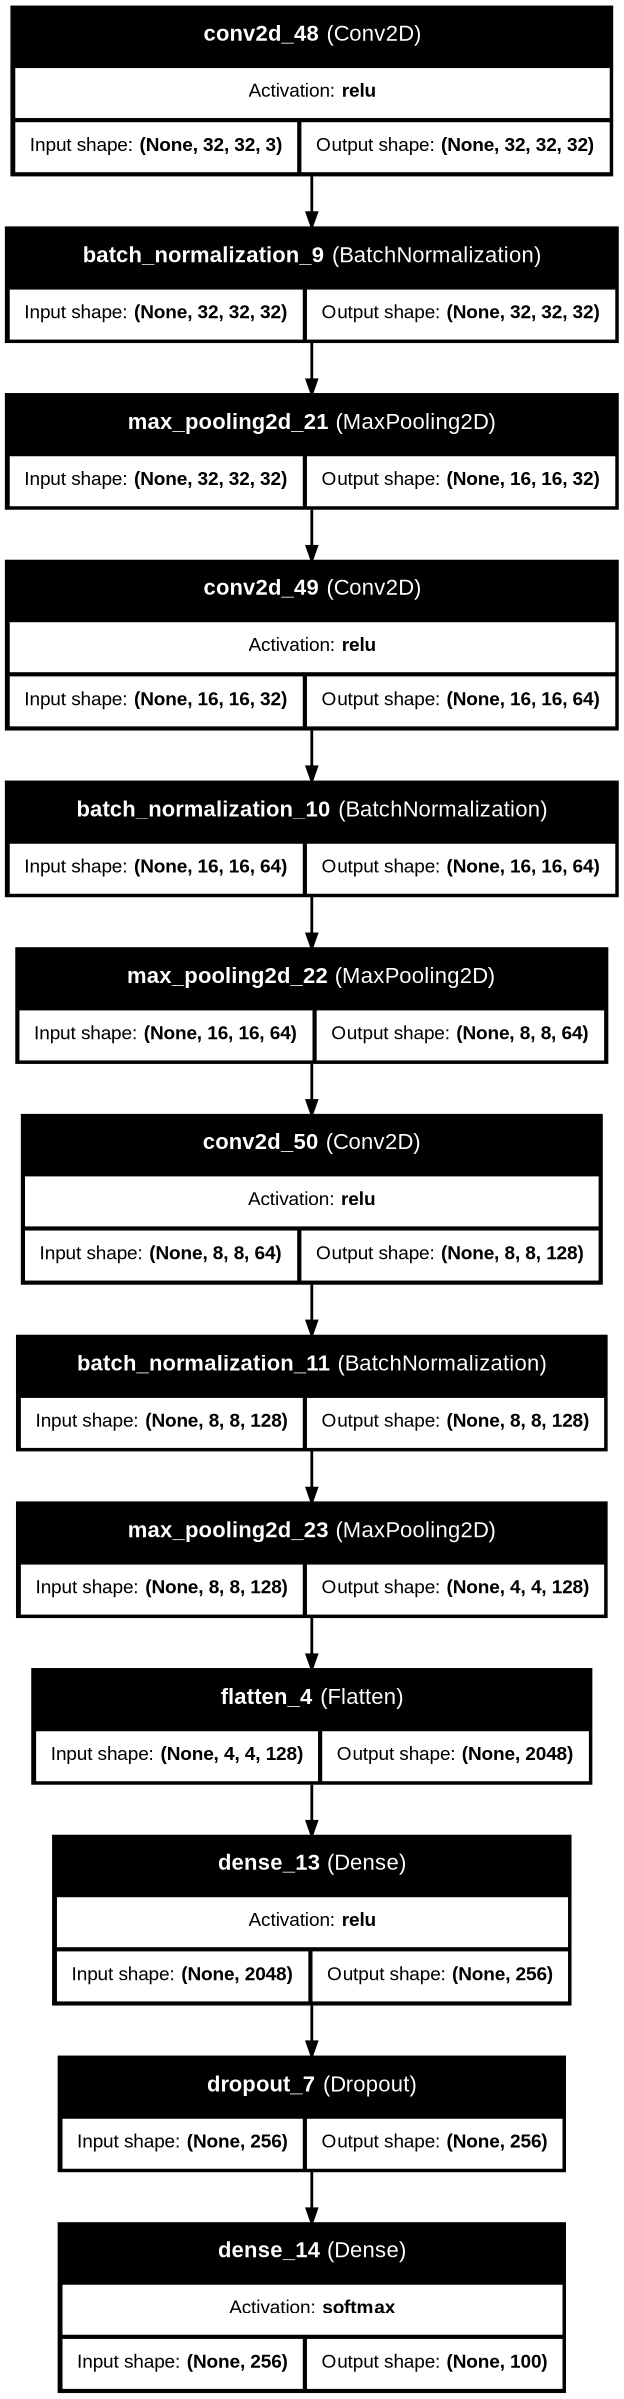

In [37]:
# Import the model plotting function
from tensorflow.keras.utils import plot_model

# Generate the CNN architecture diagram
plot_model(
    cnn_model,
    to_file="cnn_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    dpi=100
)

# Display the architecture image
from IPython.display import Image, display
display(Image(filename="cnn_architecture.png"))

## Conclusion

The Custom Convolutional Neural Network (CNN) was trained and evaluated on the CIFAR-100 dataset, achieving a test accuracy of 37.15%. The model uses three convolutional blocks with batch normalization and max pooling to extract image features. A fully connected layer and dropout were used for classification and to help reduce overfitting.

#VGG 16 Model

In [29]:
# Import required libraries
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models

# Prepare labels as integer values
y_train = y_train.reshape(-1).astype("int32")
y_test = y_test.reshape(-1).astype("int32")

# Apply VGG-16 preprocessing
# The original images are already normalized to 0-1
x_train_vgg = tf.keras.applications.vgg16.preprocess_input(
    x_train * 255.0
)

x_test_vgg = tf.keras.applications.vgg16.preprocess_input(
    x_test * 255.0
)

# Display dataset shapes
print("Training images:", x_train_vgg.shape)
print("Testing images:", x_test_vgg.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)
Training labels: (50000,)
Testing labels: (10000,)


#Create VGG Model

In [30]:
# Load the pretrained VGG-16 convolutional base
vgg_base = tf.keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(32, 32, 3)
)

# Freeze the pretrained convolutional layers
vgg_base.trainable = False

# Create the VGG-16 model for CIFAR-100 classification
vgg16_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    vgg_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(100, activation="softmax")
])

# Compile the model
vgg16_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
vgg16_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,871,716 (56.73 MB)

 Trainable params: 157,028 (613.39 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

#Train VGG Model

In [31]:
# Create an EarlyStopping callback
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the VGG-16 model
vgg_history = vgg16_model.fit(
    x_train_vgg,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.1087 - loss: 5.5500 - val_accuracy: 0.2101 - val_loss: 3.5712
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.2032 - loss: 3.4898 - val_accuracy: 0.2686 - val_loss: 3.0861
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.2493 - loss: 3.1330 - val_accuracy: 0.2932 - val_loss: 2.9026
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.2794 - loss: 2.9202 - val_accuracy: 0.3076 - val_loss: 2.8317
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.3030 - loss: 2.7863 - val_accuracy: 0.3237 - val_loss: 2.7916
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.3192 - loss: 2.6866 - val_accuracy: 0.3219 - val_loss: 2.7615
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.3342 - loss: 2.6021 - val_accuracy: 0.3356 - val_loss: 2.7816
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.3503 - loss: 2.5241 - val_acc

#Evaluation

In [32]:
# Evaluate the trained VGG-16 model on test data
vgg_test_loss, vgg_test_accuracy = vgg16_model.evaluate(
    x_test_vgg,
    y_test,
    verbose=1
)

# Display the evaluation results
print("VGG-16 Test Loss:", round(vgg_test_loss, 4))
print("VGG-16 Test Accuracy:", round(vgg_test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.3338 - loss: 2.7229
VGG-16 Test Loss: 2.7229
VGG-16 Test Accuracy: 33.38 %


In [34]:
# Import evaluation metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import numpy as np

# Generate predictions on the test dataset
y_pred_prob = vgg16_model.predict(x_test_vgg)

# Convert predicted probabilities to class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Display the classification report
print("VGG-16 Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    digits=4,
    zero_division=0
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step
VGG-16 Classification Report:
              precision    recall  f1-score   support

           0     0.6875    0.6600    0.6735       100
           1     0.3431    0.3500    0.3465       100
           2     0.3286    0.2300    0.2706       100
           3     0.2462    0.1600    0.1939       100
           4     0.1225    0.3100    0.1756       100
           5     0.2500    0.2200    0.2340       100
           6     0.3387    0.2100    0.2593       100
           7     0.3652    0.4200    0.3907       100
           8     0.3229    0.3100    0.3163       100
           9     0.3649    0.5400    0.4355       100
          10     0.4211    0.2400    0.3057       100
          11     0.2121    0.1400    0.1687       100
          12     0.4844    0.3100    0.3780       100
          13     0.2131    0.2600    0.2342       100
          14     0.3182    0.1400    0.1944       100
          15     0.1579    0.1800    0.1682       100
         

The VGG-16 model was trained and evaluated on the CIFAR-100 dataset using transfer learning and achieved a test accuracy of 33.38%. The model used pretrained ImageNet weights to extract image features and classify images into 100 classes.

Graphs

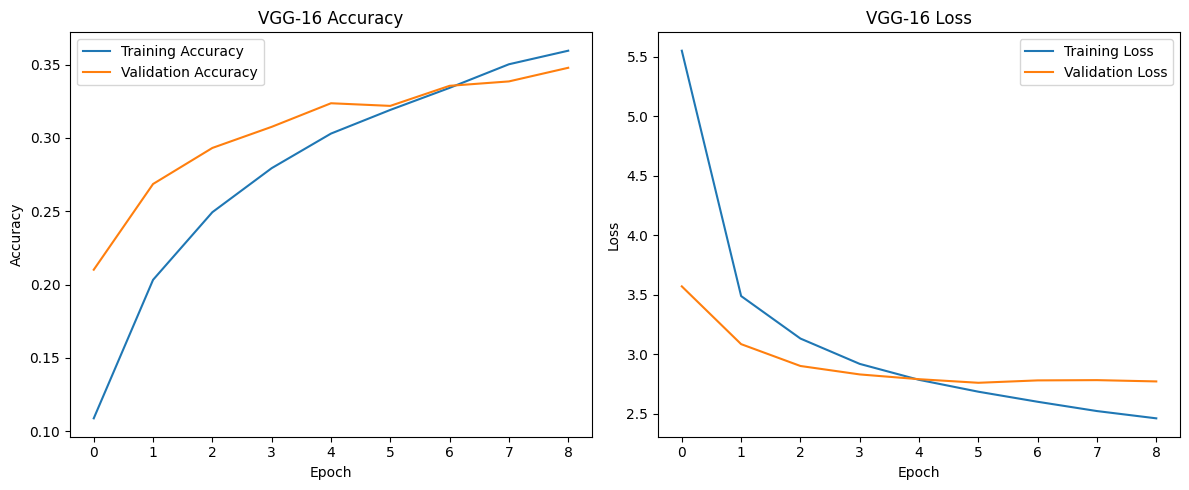

In [33]:
# Plot VGG-16 training and validation accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(vgg_history.history["accuracy"], label="Training Accuracy")
plt.plot(vgg_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("VGG-16 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Plot VGG-16 training and validation loss
plt.subplot(1, 2, 2)
plt.plot(vgg_history.history["loss"], label="Training Loss")
plt.plot(vgg_history.history["val_loss"], label="Validation Loss")
plt.title("VGG-16 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

#VGG Architechture

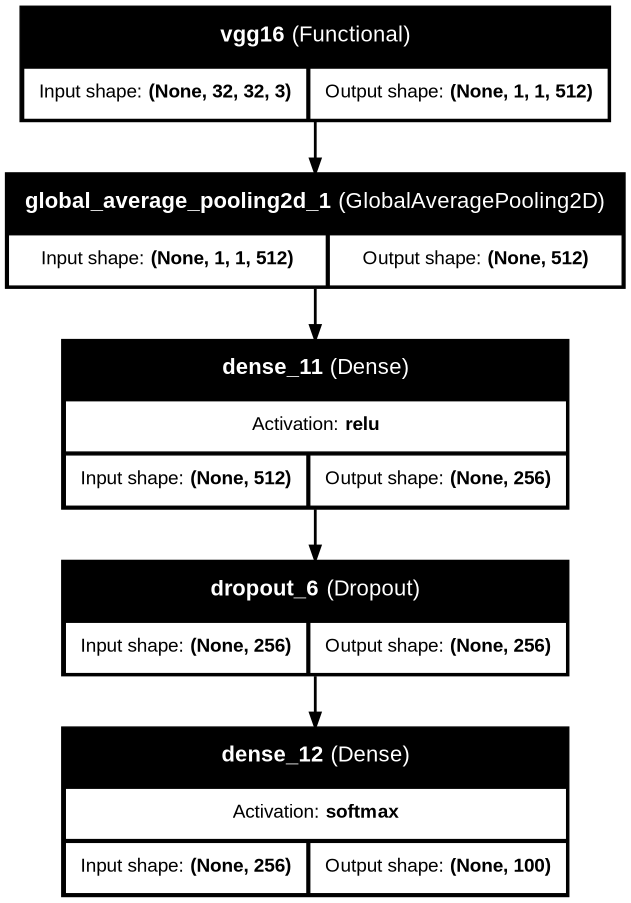

In [38]:
# Generate the VGG-16 architecture diagram
plot_model(
    vgg16_model,
    to_file="vgg16_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    dpi=100
)

# Display the architecture image
display(Image(filename="vgg16_architecture.png"))

CNN vs VGG 16 Comparison Graph

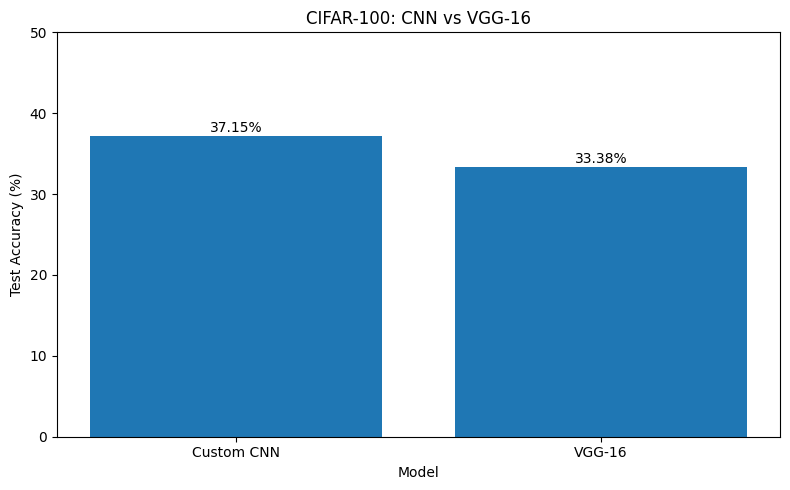

In [35]:
# Compare the test accuracy of both models
import matplotlib.pyplot as plt

model_names = ["Custom CNN", "VGG-16"]
test_accuracies = [37.15, 33.38]

# Plot the accuracy comparison
plt.figure(figsize=(8, 5))
bars = plt.bar(model_names, test_accuracies)

plt.title("CIFAR-100: CNN vs VGG-16")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 50)

# Display accuracy values above the bars
for bar, accuracy in zip(bars, test_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

#Conclusion

The Custom CNN achieved 3.77 percentage points higher test accuracy than VGG-16. It also obtained a lower test loss and higher macro precision, recall, and F1-score. Therefore, the Custom CNN performed better than the VGG-16 transfer-learning model under the experimental settings used.

#Overall Conclusion

This project compared a custom CNN and a pretrained VGG-16 model for image classification on the CIFAR-100 dataset. The Custom CNN achieved a test accuracy of 37.15%, while VGG-16 achieved 33.38%. Based on these results, the Custom CNN was the better-performing model in this experiment.